# Bat_Transformer vs. MLP-only baseline vs. GLM family

Compares five encoders on the same train/valid/test splits used in
`preprocess-data-v0j-share.ipynb`:

1. **Transformer** — full `Bat_Transformer` with RoPE attention.
2. **MLP only** — same architecture with `use_attention=False`, so each
   `TransformerEncoderRoPE` block is replaced by a per-timestep
   `_PerTimestepFFN` (LayerNorm + GELU FFN + residual). No temporal mixing,
   no positional info — RoPE is dropped along with the attention.
3. **GLM** — `GLM_3DCosineBasis`, position-only (lag=0).
4. **GLM + lags** — same with time-lagged positions in `[-1, +1] s`.
5. **GLM + lags + kinematics** — adds speed + velocity-direction bumps + IMU
   (uses the kinematics dataloader: `use_speed_head_dir=True, use_IMU_flag=True`).

Comparison metrics: per-neuron Poisson FDE and Pearson correlation on the
held-out test set, broken down by flight filter (all / in-domain / OOD).

In [81]:
%load_ext autoreload
%autoreload 2

import os
import sys
from copy import deepcopy

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import torch
from torch import nn
from scipy.stats import wilcoxon

sys.path.append(os.path.expanduser('~/Documents/code/digitalbat'))
from digitalbat.datasets.data import bat_data_loader
from digitalbat.datasets.defaults import DEFAULT_SESSION_NAMES, make_data_config
from digitalbat.models.former import Bat_Transformer
from digitalbat.models.former_defaults import (
    DEFAULT_LR, DEFAULT_WEIGHT_DECAY,
    make_model_config, make_model_name, make_trainer_config,
)
from digitalbat.models.glm import (
    GLM_3DCosineBasis, GLM_3DCosineBasis_Kinematics,
    create_cosine_bumps_torch,
)
from digitalbat.models.layers import ELU1
from digitalbat.training.trainer import bat_former_trainer
from digitalbat.utility.utils import (
    corr, poisson_fde_population, set_random_state,
    bat_palette, parse_bat, wilcoxon_safe,
    add_significance_bracket, annotate_pvalue_corner,
)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [82]:
seed = 1
set_random_state(seed)
device = 'cuda'

# Canonical model order (used for plotting / DataFrame column order).
MODEL_ORDER = ['GLM', 'GLM + lags', 'GLM + lags + kin',
               'MLP only', 'Transformer']

# Where the pretrained checkpoints live. Defaults match
# preprocess-data-v0j-share.ipynb's canonical paths; override here if different.
BAT_FORMER_CKPT = make_model_name(
    seed, DEFAULT_LR, DEFAULT_WEIGHT_DECAY,
    out_dir='./out/bat_former', suffix='',
)
BAT_FORMER_NOATTN_CKPT = make_model_name(
    seed, DEFAULT_LR, DEFAULT_WEIGHT_DECAY,
    out_dir='./out/bat_former_no_attn', suffix='',
)
os.makedirs(os.path.dirname(BAT_FORMER_NOATTN_CKPT), exist_ok=True)

# GLM checkpoint paths use the tag pattern from the reference notebook:
#   ./out/bat_glm/bat_{tag}_seed_{seed}_wd_{wd}.pth
GLM_WEIGHT_DECAYS = {'GLM': 1.0, 'GLM + lags': 10.0, 'GLM + lags + kin': 10.0}

def _glm_ckpt(name, wd):
    tag = name.lower().replace(' + ', '_').replace(' ', '_')
    return f'./out/bat_glm/bat_{tag}_seed_{seed}_wd_{wd}.pth'

CKPT_PATHS = {
    'Transformer': BAT_FORMER_CKPT,
    'MLP only': BAT_FORMER_NOATTN_CKPT,
    'GLM': _glm_ckpt('GLM', GLM_WEIGHT_DECAYS['GLM']),
    'GLM + lags': _glm_ckpt('GLM + lags', GLM_WEIGHT_DECAYS['GLM + lags']),
    'GLM + lags + kin': _glm_ckpt('GLM + lags + kin', GLM_WEIGHT_DECAYS['GLM + lags + kin']),
}
for name, path in CKPT_PATHS.items():
    print(f'  {name:<22} -> {path}  (exists={os.path.exists(path)})')

BAT_PALETTE = bat_palette()

  Transformer            -> ./out/bat_former/bat_former_seed_1_lr_1.00e-02_wd_1.00e-02.pth  (exists=True)
  MLP only               -> ./out/bat_former_no_attn/bat_former_seed_1_lr_1.00e-02_wd_1.00e-02.pth  (exists=True)
  GLM                    -> ./out/bat_glm/bat_glm_seed_1_wd_1.0.pth  (exists=True)
  GLM + lags             -> ./out/bat_glm/bat_glm_lags_seed_1_wd_10.0.pth  (exists=True)
  GLM + lags + kin       -> ./out/bat_glm/bat_glm_lags_kin_seed_1_wd_10.0.pth  (exists=True)


## Data loader

Single call to `bat_data_loader` shared by both models so the train/valid/test
splits and the standardization stats are identical.

In [ ]:
data_config = make_data_config()
dataloaders, behavior_dim, unit_num_dict, meta_info_dict = bat_data_loader(**data_config)
print(f'Base dataloader: behavior_dim={behavior_dim}, {len(unit_num_dict)} sessions')

# Kinematics dataloader for the `GLM + lags + kin` variant: adds speed,
# head direction (vel_unit), and IMU to the behavior vector
# (dims: 0-2=xyz, 3=speed, 4-6=vel_unit, 7-9=imu_acc, 10-12=imu_gyr).
data_config_kin = {**data_config, 'use_speed_head_dir': True, 'use_IMU_flag': True}
dataloaders_kin, behavior_dim_kin, unit_num_dict_kin, meta_info_dict_kin = bat_data_loader(**data_config_kin)
print(f'Kinematics dataloader: behavior_dim={behavior_dim_kin}')

In [83]:
# Per-model (dataloaders, meta_info_dict) routing.
DATA_BY_MODEL = {
    'Transformer':       (dataloaders,     meta_info_dict),
    'MLP only':          (dataloaders,     meta_info_dict),
    'GLM':               (dataloaders,     meta_info_dict),
    'GLM + lags':        (dataloaders,     meta_info_dict),
    'GLM + lags + kin':  (dataloaders_kin, meta_info_dict_kin),
}

## Models

Build all five encoders. The two `Bat_Transformer` variants share `make_model_config`
(only `use_attention` differs). The three GLM variants follow the same configs as
`preprocess-data-v0j-share.ipynb`.

In [84]:
# All five models use the full 18-session unit_num_dict (kin uses the kinematics
# variant). If an on-disk GLM checkpoint was trained on a subset, the train cell
# below will detect the key mismatch and retrain (overwriting the old ckpt).
glm_common = dict(
    n_bases_per_dim=16, pos_range=(-3.0, 3.0),
    width_to_spacing_ratio=4, activation='exp',
    bin_width=data_config['bin_width'],
)
glm_lags = np.arange(-1.0, 1.0 + 1e-9, 0.2).tolist()

glm_configs_by_name = {
    'GLM': (GLM_3DCosineBasis,
            dict(**glm_common, output_dim_dict=unit_num_dict)),
    'GLM + lags': (GLM_3DCosineBasis,
                   dict(**glm_common, output_dim_dict=unit_num_dict,
                        lag_seconds=glm_lags)),
    'GLM + lags + kin': (GLM_3DCosineBasis_Kinematics, dict(
        output_dim_dict=unit_num_dict_kin,
        behavior_stats={s: (meta_info_dict_kin['behavior_mean'][s],
                            meta_info_dict_kin['behavior_std'][s])
                        for s in meta_info_dict_kin['behavior_mean']},
        n_bases_per_dim=16, pos_range=(-3.0, 3.0), width_to_spacing_ratio=4,
        activation='exp', bin_width=data_config['bin_width'],
        lag_seconds=glm_lags, n_vel_bumps=8, vel_width_ratio=4,
    )),
}

base_model_config = make_model_config(behavior_dim, unit_num_dict, meta_info_dict)
transformer_noattn_cfg = {**base_model_config, 'use_attention': False}

models = {
    'Transformer': Bat_Transformer(**base_model_config),
    'MLP only':    Bat_Transformer(**transformer_noattn_cfg),
}
for name in ['GLM', 'GLM + lags', 'GLM + lags + kin']:
    cls, cfg = glm_configs_by_name[name]
    models[name] = cls(**cfg)

def _count_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)
for name in MODEL_ORDER:
    print(f'  {name:<22}: {_count_params(models[name]):>10,} parameters')

def _ckpt_is_compatible(model, path):
    """Return True iff loading `path` into `model` would succeed under strict=True."""
    if not os.path.exists(path):
        return False
    try:
        state = torch.load(path, map_location='cpu', weights_only=False)
    except Exception:
        return False
    model_keys = set(model.state_dict().keys())
    ckpt_keys = set(state.keys())
    if model_keys != ckpt_keys:
        return False
    for k in model_keys:
        if model.state_dict()[k].shape != state[k].shape:
            return False
    return True

ckpt_compat = {name: _ckpt_is_compatible(models[name], CKPT_PATHS[name]) for name in MODEL_ORDER}
print()
for name in MODEL_ORDER:
    print(f'  {name:<22}: ckpt compatible = {ckpt_compat[name]}')

GLM: 11 lags x 4096 spatial = 45056 features, lag_bins=[-10, -8, -6, -4, -2, 0, 2, 4, 6, 8, 10]
GLM Kinematics: 11 lags x (4096 spatial + 24 vel + 7 speed+IMU) = 45397 features
  GLM                   : 13,802,793 parameters
  GLM + lags            : 151,797,033 parameters
  GLM + lags + kin      : 152,945,862 parameters
  MLP only              :    113,481 parameters
  Transformer           :    117,769 parameters

  GLM                   : ckpt compatible = True
  GLM + lags            : ckpt compatible = True
  GLM + lags + kin      : ckpt compatible = True
  MLP only              : ckpt compatible = True
  Transformer           : ckpt compatible = True


### Sanity-check the 3D cosine basis

Diagnostic plots for the raised-cosine basis the GLMs use (only needs to be
re-run if `n_bases_per_dim` or `pos_range` change):

1. 1D cosine bumps along one axis — should tile evenly (sum ≈ constant in interior).
2. A few selected 3D basis functions as 3D scatter (point size ∝ basis value).
3. Sum-of-bases slices — should be roughly constant in the interior of the tiled cube.
4. Design matrix on a real test batch for each GLM variant.

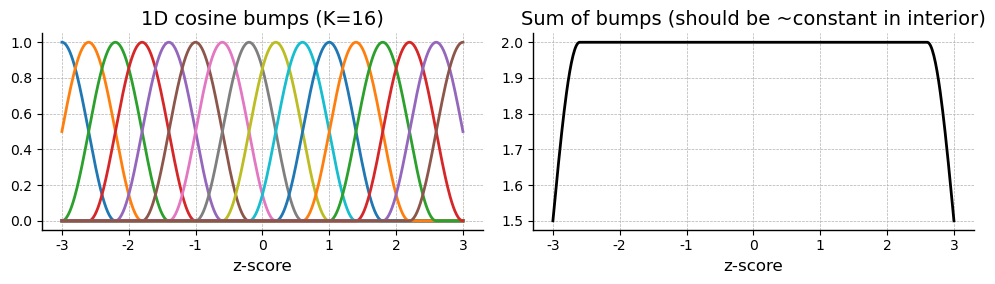

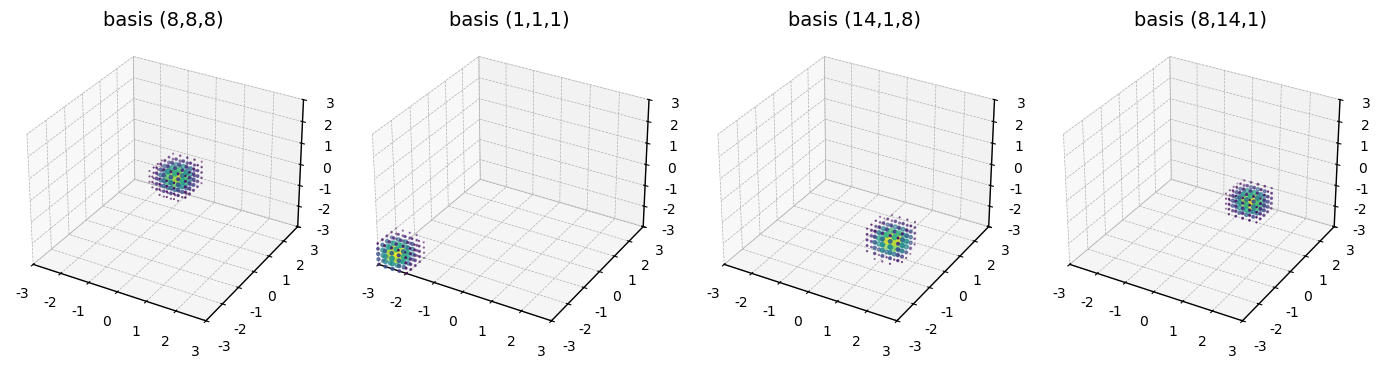

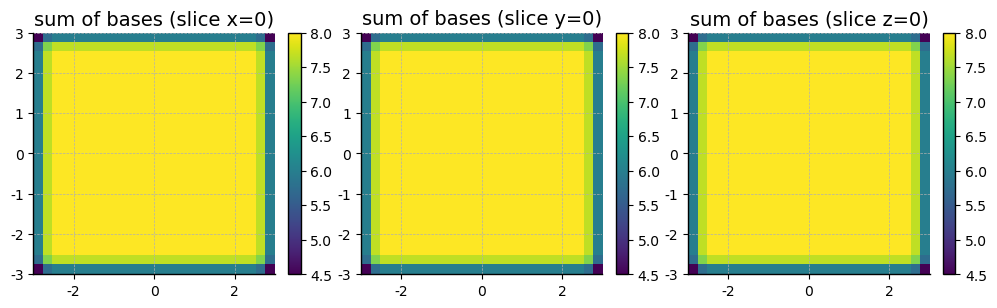

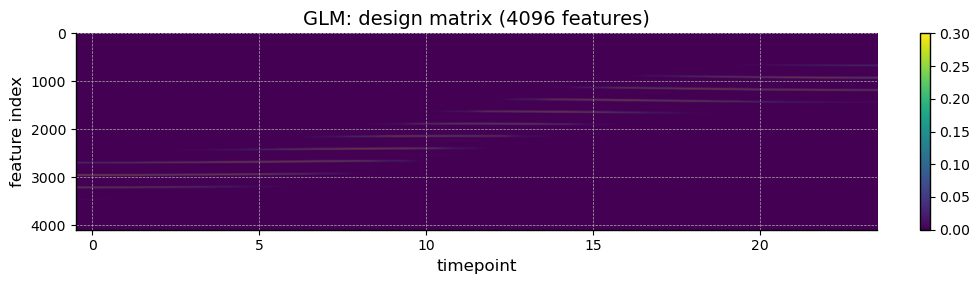

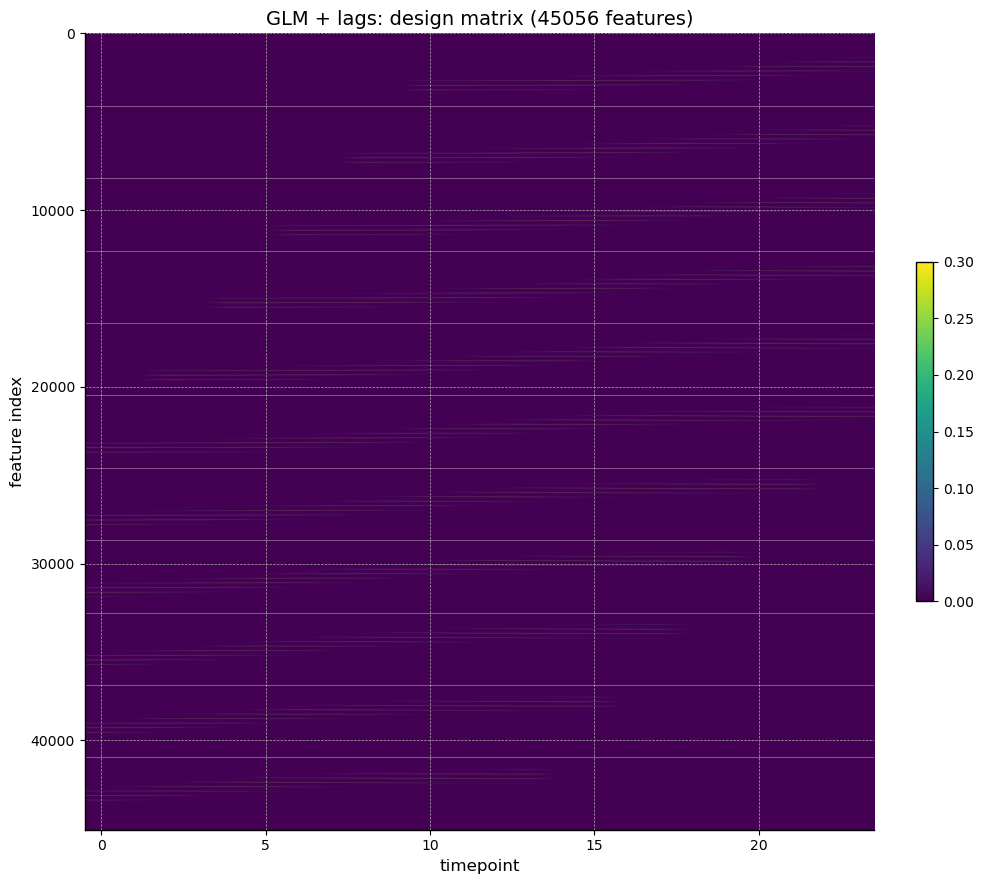

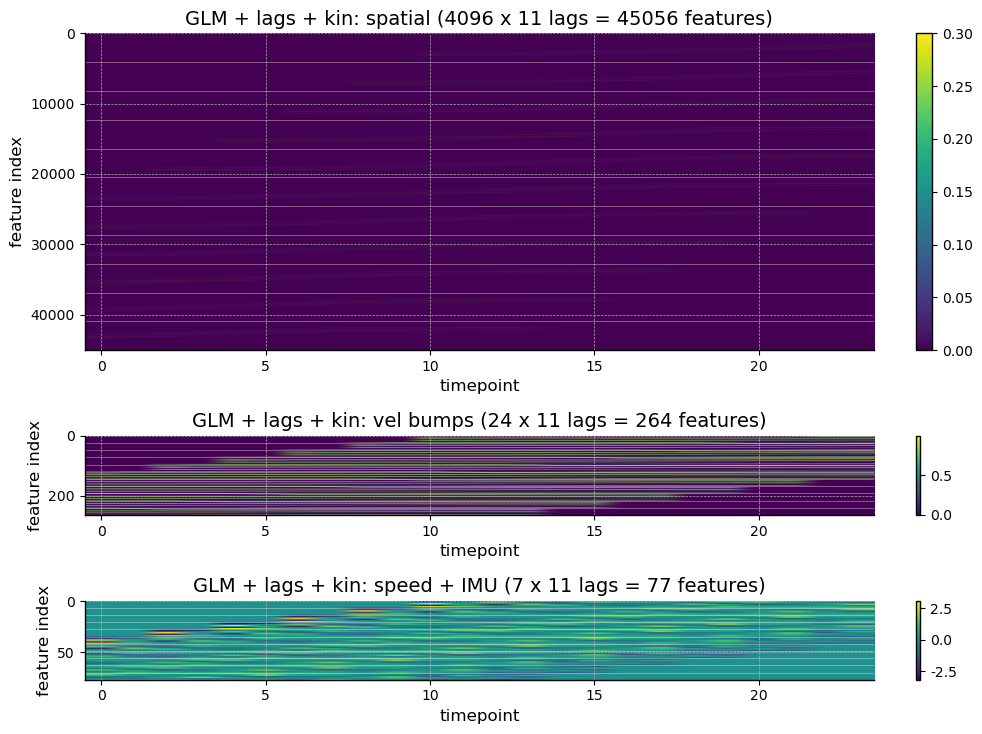

In [85]:
centers = models['GLM'].centers.cpu().numpy()
width = models['GLM'].width
K = models['GLM'].n_bases_per_dim
lo, hi = float(centers[0]), float(centers[-1])

# --- (1) 1D bumps along one axis ---
xs = torch.linspace(lo, hi, 500)
b1d = create_cosine_bumps_torch(xs, models['GLM'].centers, width).cpu().numpy()
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].plot(xs.numpy(), b1d)
axes[0].set(title=f'1D cosine bumps (K={K})', xlabel='z-score')
axes[1].plot(xs.numpy(), b1d.sum(axis=1), 'k')
axes[1].set(title='Sum of bumps (should be ~constant in interior)', xlabel='z-score')
plt.tight_layout(); plt.show()

# --- (2) Selected 3D basis functions over a 3D grid ---
N_GRID = 25
g_pts = torch.linspace(lo, hi, N_GRID)
X3, Y3, Z3 = torch.meshgrid(g_pts, g_pts, g_pts, indexing='ij')
grid = torch.stack([X3.flatten(), Y3.flatten(), Z3.flatten()], dim=-1)
bx = create_cosine_bumps_torch(grid[:, 0], models['GLM'].centers, width)
by = create_cosine_bumps_torch(grid[:, 1], models['GLM'].centers, width)
bz = create_cosine_bumps_torch(grid[:, 2], models['GLM'].centers, width)
bases_grid = (bx.unsqueeze(-1).unsqueeze(-1)
              * by.unsqueeze(-2).unsqueeze(-1)
              * bz.unsqueeze(-2).unsqueeze(-2)).flatten(-3).cpu().numpy()

chosen = [(K // 2, K // 2, K // 2), (1, 1, 1), (K - 2, 1, K // 2), (K // 2, K - 2, 1)]
fig = plt.figure(figsize=(14, 3.5))
for i, (ix, iy, iz) in enumerate(chosen):
    flat_idx = ix * K * K + iy * K + iz
    vals = bases_grid[:, flat_idx]
    keep = vals > 0.01
    ax = fig.add_subplot(1, 4, i + 1, projection='3d')
    ax.scatter(grid[keep, 0].cpu(), grid[keep, 1].cpu(), grid[keep, 2].cpu(),
               c=vals[keep], s=20 * vals[keep], cmap='viridis')
    ax.set(title=f'basis ({ix},{iy},{iz})',
           xlim=(lo, hi), ylim=(lo, hi), zlim=(lo, hi))
plt.tight_layout(); plt.show()

# --- (3) Sum-of-bases slices ---
total = bases_grid.sum(axis=1).reshape(N_GRID, N_GRID, N_GRID)
mid = N_GRID // 2
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for ax, sl, sname in zip(axes,
                         [total[mid], total[:, mid], total[:, :, mid]],
                         ['x=0', 'y=0', 'z=0']):
    im = ax.imshow(sl, extent=[lo, hi, lo, hi], origin='lower')
    ax.set_title(f'sum of bases (slice {sname})')
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()

# --- (4) Design matrix on a real test batch for each GLM variant ---
session_name = list(dataloaders['test'].keys())[0]
batch = next(iter(dataloaders['test'][session_name]))
batch_kin = next(iter(dataloaders_kin['test'][session_name]))

for name in ['GLM', 'GLM + lags', 'GLM + lags + kin']:
    model = models[name]
    if 'kin' in name:
        xr, mr = batch_kin.behavior, batch_kin.mask
        with torch.no_grad():
            design = model._make_design(xr, mr, session_name=session_name)
    else:
        xr, mr = batch.behavior, batch.mask
        with torch.no_grad():
            design = model._make_design(xr, mr)

    valid = mr[0] == 1.0
    design_valid = design[0, valid].cpu().numpy()
    n_features = design_valid.shape[1]
    n_lags = len(model.lag_bins)

    if 'kin' in name:
        K3 = model.n_bases_per_dim ** 3
        n_vel = model.n_vel_bumps * 3
        n_extra = 7  # speed (1) + IMU (6)
        per_lag = K3 + n_vel + n_extra
        groups = [
            ('spatial', 0, K3, 0.3),
            ('vel bumps', K3, K3 + n_vel, None),
            ('speed + IMU', K3 + n_vel, per_lag, None),
        ]
        fig, axes = plt.subplots(len(groups), 1, figsize=(10, 2.5 * len(groups)),
                                  height_ratios=[4, 1, 1])
        for ax, (gname, g_start, g_end, vmax) in zip(axes, groups):
            blocks = [design_valid[:, lag * per_lag + g_start: lag * per_lag + g_end]
                      for lag in range(n_lags)]
            block = np.concatenate(blocks, axis=1)
            im = ax.imshow(block.T, aspect='auto', cmap='viridis', vmax=vmax)
            g_size = g_end - g_start
            ax.set(xlabel='timepoint', ylabel='feature index',
                   title=f'{name}: {gname} ({g_size} x {n_lags} lags = {block.shape[1]} features)')
            if n_lags > 1:
                for k in range(1, n_lags):
                    ax.axhline(k * g_size - 0.5, color='white', lw=0.5, alpha=0.5)
            plt.colorbar(im, ax=ax, fraction=0.02)
        plt.tight_layout(); plt.show()
    else:
        fig, ax = plt.subplots(figsize=(10, 3 * max(n_lags // 3, 1)))
        im = ax.imshow(design_valid.T, aspect='auto', cmap='viridis', vmax=0.3)
        ax.set(xlabel='timepoint', ylabel='feature index',
               title=f'{name}: design matrix ({n_features} features)')
        if n_lags > 1:
            K3 = n_features // n_lags
            for k in range(1, n_lags):
                ax.axhline(k * K3 - 0.5, color='white', lw=0.5, alpha=0.5)
        plt.colorbar(im, ax=ax, fraction=0.02)
        plt.tight_layout(); plt.show()

## Train missing checkpoints (with weight-decay tuning for GLMs)

For each model with a missing or incompatible checkpoint:

- **MLP only**: trains once with `DEFAULT_WEIGHT_DECAY`.
- **Each GLM variant**: grid-searches `weight_decay ∈ WD_CANDIDATES`, picking the
  value with the best median val FDE. Each candidate warm-starts from the
  previous best (so successive candidates need fewer epochs). The discovered
  `best_wd` updates `GLM_WEIGHT_DECAYS` and `CKPT_PATHS` in place, and the
  trained weights are saved under the new path.

If a checkpoint already exists and matches the current architecture/sessions,
training is skipped entirely.

In [86]:
WD_CANDIDATES = [1.0, 10.0, 100.0]

# --- Train MLP only if missing/incompatible ---
if ckpt_compat['MLP only']:
    print(f'[MLP only] checkpoint exists and is compatible — skipping training.')
else:
    print(f'[MLP only] training fresh ...')
    set_random_state(seed)
    models['MLP only'] = Bat_Transformer(**transformer_noattn_cfg).to(device)
    trainer_config = make_trainer_config(
        model=models['MLP only'],
        dataloaders=dataloaders, device=device,
        model_name=BAT_FORMER_NOATTN_CKPT,
        lr=DEFAULT_LR, weight_decay=DEFAULT_WEIGHT_DECAY,
    )
    best_acc, _, acc_curve = bat_former_trainer(**trainer_config)
    print(f'  best val FDE (median): {best_acc:.4f}')
    plt.figure(figsize=(4, 3))
    plt.plot(acc_curve)
    plt.xlabel('Epoch'); plt.ylabel('Val FDE (median)')
    plt.title('MLP only training curve'); plt.tight_layout(); plt.show()

# --- For each GLM variant: grid-search wd if missing/incompatible ---
for name in ['GLM', 'GLM + lags', 'GLM + lags + kin']:
    if ckpt_compat[name]:
        print(f'[{name}] checkpoint exists and is compatible — skipping training.')
        continue

    print(f'\n[{name}] tuning weight_decay over {WD_CANDIDATES} ...')
    cls, cfg = glm_configs_by_name[name]
    dls, _ = DATA_BY_MODEL[name]

    best_wd, best_val, best_weights = None, -np.inf, None
    wd_results = []
    for wd in WD_CANDIDATES:
        set_random_state(seed)
        glm_tune = cls(**cfg).to(device)
        if best_weights is not None:  # warm-start from previous best
            glm_tune.load_state_dict(deepcopy(best_weights))
        val_score, weights, _ = bat_former_trainer(
            model=glm_tune, dataloaders=dls, device=device,
            n_epochs=1000, lr=DEFAULT_LR, weight_decay=wd,
            loss_fn=nn.PoissonNLLLoss(log_input=False),
            valid_fn=poisson_fde_population, valid_stat='median',
            early_stopping_patience=20, save_model=False,
        )
        wd_results.append({'wd': wd, 'val_score': val_score})
        print(f'  wd={wd:>6}: val FDE (median) = {val_score:+.4f}')
        if val_score > best_val:
            best_val, best_wd, best_weights = val_score, wd, deepcopy(weights)

    # Update bookkeeping + save under the discovered wd's filename
    GLM_WEIGHT_DECAYS[name] = best_wd
    new_path = _glm_ckpt(name, best_wd)
    CKPT_PATHS[name] = new_path
    os.makedirs(os.path.dirname(new_path), exist_ok=True)
    torch.save(best_weights, new_path)
    print(f'  best wd = {best_wd} (val FDE = {best_val:+.4f}); saved to {new_path}')

    # Load best weights into the canonical model so downstream cells can use it.
    models[name] = cls(**cfg).to(device)
    models[name].load_state_dict(best_weights)
    ckpt_compat[name] = True

    # Tuning curve
    fig, ax = plt.subplots(figsize=(4, 3))
    ax.semilogx([r['wd'] for r in wd_results], [r['val_score'] for r in wd_results], 'o-')
    ax.axvline(best_wd, color='r', ls='--', label=f'best={best_wd}')
    ax.set_xlabel('weight_decay'); ax.set_ylabel('val FDE (median)')
    ax.set_title(f'{name}: WD tuning'); ax.legend(); plt.tight_layout(); plt.show()

[MLP only] checkpoint exists and is compatible — skipping training.
[GLM] checkpoint exists and is compatible — skipping training.
[GLM + lags] checkpoint exists and is compatible — skipping training.
[GLM + lags + kin] checkpoint exists and is compatible — skipping training.


## Load all five checkpoints

In [87]:
for name in MODEL_ORDER:
    path = CKPT_PATHS[name]
    state = torch.load(path, map_location=device)
    missing, unexpected = models[name].load_state_dict(state, strict=True)
    assert not missing and not unexpected, f'{name}: missing={missing}, unexpected={unexpected}'
    models[name] = models[name].to(device).eval()
    print(f'[{name}] loaded {path}')

[GLM] loaded ./out/bat_glm/bat_glm_seed_1_wd_1.0.pth
[GLM + lags] loaded ./out/bat_glm/bat_glm_lags_seed_1_wd_10.0.pth
[GLM + lags + kin] loaded ./out/bat_glm/bat_glm_lags_kin_seed_1_wd_10.0.pth
[MLP only] loaded ./out/bat_former_no_attn/bat_former_seed_1_lr_1.00e-02_wd_1.00e-02.pth
[Transformer] loaded ./out/bat_former/bat_former_seed_1_lr_1.00e-02_wd_1.00e-02.pth


## Evaluation

Copy of `evaluate_model` from `preprocess-data-v0j-share.ipynb` so this notebook
is self-contained. Each model is evaluated against its routed dataloader
(`DATA_BY_MODEL[name]`): base for everything except `GLM + lags + kin`, which
uses the kinematics dataloader.

In [88]:
def evaluate_model(model, dataloaders, valid_fn, device, flight_filter=None, meta_info_dict=None):
    """Evaluate model on test data; returns {session_name: per-neuron scores}."""
    results = {}
    model.eval()
    for session_name, session_data in dataloaders['test'].items():
        if flight_filter == 'ood':
            target_types = np.array(meta_info_dict['flight_type_test_ood'][session_name], dtype=int)
            if target_types.size == 0:
                results[session_name] = np.array([])
                continue
        elif flight_filter == 'indomain':
            target_types = np.array(meta_info_dict['flight_type_test_indomain'][session_name], dtype=int)
        else:
            target_types = None

        y_val_list, y_pred_list = [], []
        for batch in session_data:
            X_val = batch.behavior.to(device)
            y_val = batch.spike.to(device)
            mask_val = batch.mask.to(device)
            if target_types is not None:
                batch_mask = np.isin(batch.flight_type_index.numpy(), target_types)
                if not batch_mask.any():
                    continue
                X_val = X_val[batch_mask]
                y_val = y_val[batch_mask]
                mask_val = mask_val[batch_mask]
            y_pred = model(session_name, X_val, mask_val)
            y_val_list.append(y_val[mask_val == 1.0].detach().cpu().numpy())
            y_pred_list.append(y_pred[mask_val == 1.0].detach().cpu().numpy())
        if y_val_list:
            results[session_name] = valid_fn(np.vstack(y_val_list), np.vstack(y_pred_list))
        else:
            results[session_name] = np.array([])
    return results

In [89]:
metrics = {
    'corr': lambda y_true, y_pred: corr(y_true, y_pred, axis=0),
    'fde':  lambda y_true, y_pred: poisson_fde_population(y_true, y_pred),
}
flight_filters = [None, 'ood', 'indomain']

results_by_model = {name: {} for name in MODEL_ORDER}
for name in MODEL_ORDER:
    dls, mi = DATA_BY_MODEL[name]
    for metric_name, valid_fn in metrics.items():
        for flight_filter in flight_filters:
            key = f'{metric_name}_{flight_filter or "all"}'
            results_by_model[name][key] = evaluate_model(
                models[name], dls, valid_fn, device,
                flight_filter=flight_filter, meta_info_dict=mi,
            )
            all_scores = np.hstack([v for v in results_by_model[name][key].values() if len(v) > 0])
            stat = np.nanmedian if 'fde' in key else np.nanmean
            print(f'  [{name:<22}] {key:<14}: {stat(all_scores):.4f}')

  [GLM                   ] corr_all      : 0.1899
  [GLM                   ] corr_ood      : 0.0724
  [GLM                   ] corr_indomain : 0.2183
  [GLM                   ] fde_all       : -0.0779
  [GLM                   ] fde_ood       : -0.4123
  [GLM                   ] fde_indomain  : -0.0531
  [GLM + lags            ] corr_all      : 0.2510
  [GLM + lags            ] corr_ood      : 0.1007
  [GLM + lags            ] corr_indomain : 0.2736
  [GLM + lags            ] fde_all       : -0.0459
  [GLM + lags            ] fde_ood       : -0.3205
  [GLM + lags            ] fde_indomain  : -0.0338
  [GLM + lags + kin      ] corr_all      : 0.2600
  [GLM + lags + kin      ] corr_ood      : 0.1060
  [GLM + lags + kin      ] corr_indomain : 0.2798
  [GLM + lags + kin      ] fde_all       : 0.0097
  [GLM + lags + kin      ] fde_ood       : -0.2570
  [GLM + lags + kin      ] fde_indomain  : 0.0220
  [MLP only              ] corr_all      : 0.1956
  [MLP only              ] corr_ood      : 

## Long-form DataFrame

One row per (model, session, neuron, metric, flight_filter). The neuron index
within a session is consistent across models (all five share `unit_num_dict` for
non-kin variants; kin uses `unit_num_dict_kin`, which has the same session keys
and the same neuron counts as the base loader).

In [90]:
rows = []
for model_name, by_key in results_by_model.items():
    for key, by_session in by_key.items():
        metric, flight_filter = key.split('_', 1)
        for session, scores in by_session.items():
            if scores.size == 0:
                continue
            bat = parse_bat(session)
            for unit, score in enumerate(scores):
                rows.append({
                    'model': model_name, 'session': session, 'bat': bat,
                    'unit': unit, 'metric': metric,
                    'flight_filter': flight_filter, 'score': score,
                })
df = pd.DataFrame(rows)
df['model'] = pd.Categorical(df['model'], categories=MODEL_ORDER, ordered=True)
df['flight_filter'] = pd.Categorical(df['flight_filter'], categories=['all', 'indomain', 'ood'], ordered=True)
print(df.shape)
df.head()

(97310, 7)


,model,session,bat,unit,metric,flight_filter,score
0,GLM,Dataset_3_14543_240419,14543,0,corr,all,0.156001
1,GLM,Dataset_3_14543_240419,14543,1,corr,all,0.433379
2,GLM,Dataset_3_14543_240419,14543,2,corr,all,0.437281
3,GLM,Dataset_3_14543_240419,14543,3,corr,all,0.074198
4,GLM,Dataset_3_14543_240419,14543,4,corr,all,0.000000


In [91]:
# Wide form (one row per neuron) so we can compute per-neuron deltas + scatters.
wide = df.pivot_table(
    index=['session', 'bat', 'unit', 'metric', 'flight_filter'],
    columns='model', values='score', observed=False,
).reset_index()
wide.head()

model,session,bat,unit,metric,flight_filter,GLM,GLM + lags,GLM + lags + kin,MLP only,Transformer
0,Dataset_1_32622_231007,32622,0,corr,all,0.077782,0.187529,0.182963,0.075545,0.153433
1,Dataset_1_32622_231007,32622,0,corr,indomain,0.153214,0.270469,0.235251,0.132776,0.263351
2,Dataset_1_32622_231007,32622,0,corr,ood,-0.112636,-0.105502,0.003149,-0.123111,-0.165422
3,Dataset_1_32622_231007,32622,0,fde,all,-0.115617,-0.042046,-0.048193,-0.001625,0.010522
4,Dataset_1_32622_231007,32622,0,fde,indomain,0.006445,0.032864,0.010742,0.011085,0.059209


## Per-session score, all five models

One paired point per session (median over neurons). Lines colored by bat
(memory rule: always use `bat_palette()`). FDE y-axis clipped to `[-1, 1]` in
the plot only — underlying values stay raw.

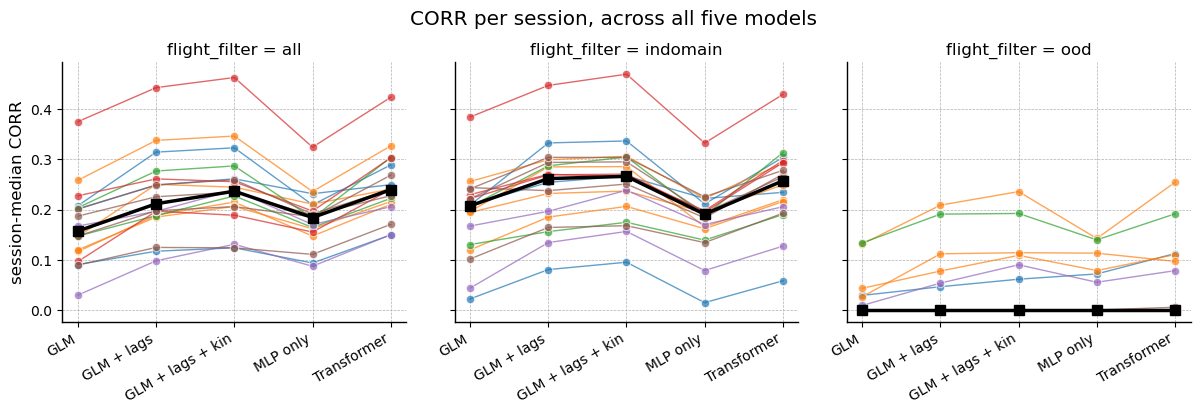

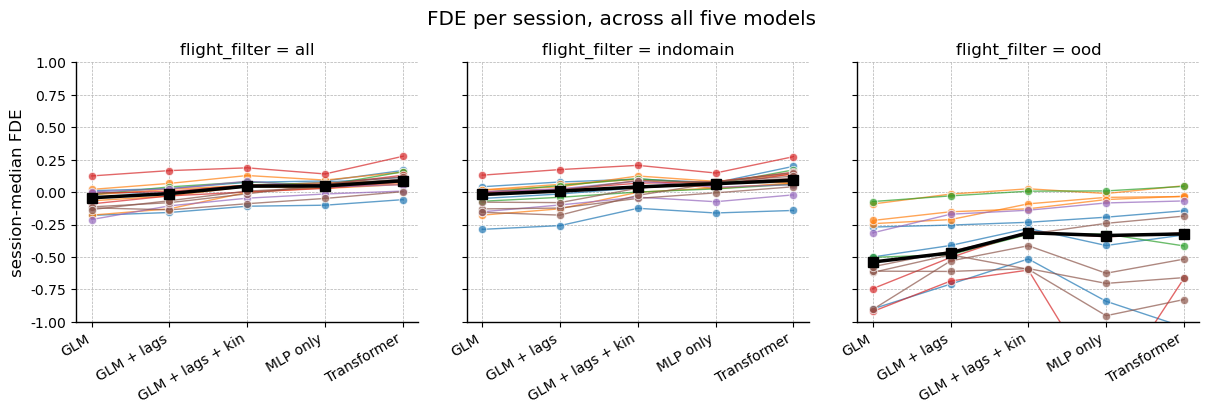

In [92]:
session_df = (
    df.groupby(['metric', 'flight_filter', 'session', 'bat', 'model'], observed=True)
      .agg(score=('score', 'median'))
      .reset_index()
)

for metric in ['corr', 'fde']:
    g = sns.FacetGrid(
        session_df[session_df['metric'] == metric],
        col='flight_filter', col_order=['all', 'indomain', 'ood'],
        height=3.6, aspect=1.15, sharex=True, sharey=True,
    )
    g.map_dataframe(
        sns.lineplot, x='model', y='score', units='session',
        hue='bat', palette=BAT_PALETTE, hue_order=list(BAT_PALETTE.keys()),
        estimator=None, marker='o', alpha=0.7, linewidth=1, legend=False,
    )
    for flight_filter, ax in g.axes_dict.items():
        # Black line connecting per-model session-medians shows the trend.
        sub = (session_df[(session_df['metric'] == metric) &
                          (session_df['flight_filter'] == flight_filter)]
               .groupby('model', observed=True)['score'].median()
               .reindex(MODEL_ORDER))
        ax.plot(range(len(sub)), sub.values, color='k', linewidth=2.5, marker='s',
                markersize=7, label='cross-session median', zorder=5)
        ax.tick_params(axis='x', rotation=30)
        for lbl in ax.get_xticklabels():
            lbl.set_horizontalalignment('right')
        if metric == 'fde':
            ax.set_ylim(-1, 1)
    g.set_axis_labels('', f'session-median {metric.upper()}')
    g.figure.suptitle(f'{metric.upper()} per session, across all five models', y=1.04)
    plt.show()

## Transformer vs. each baseline: significance

Wilcoxon signed-rank on the per-session-median scores between the full
`Transformer` and each of the four baselines (memory rule: session-level
nonparametric stats by default). Bracket + stars shown only when significant
(3 tiers, hide n.s.). Brackets stack vertically with the longest span at the
bottom.

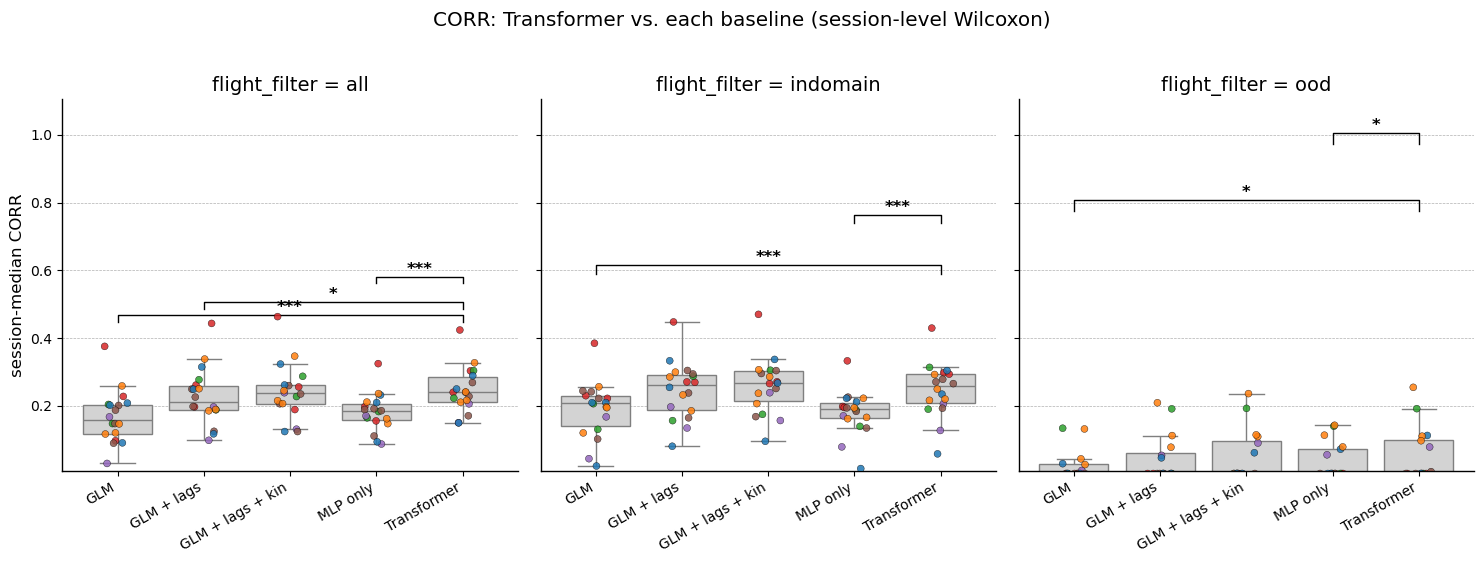

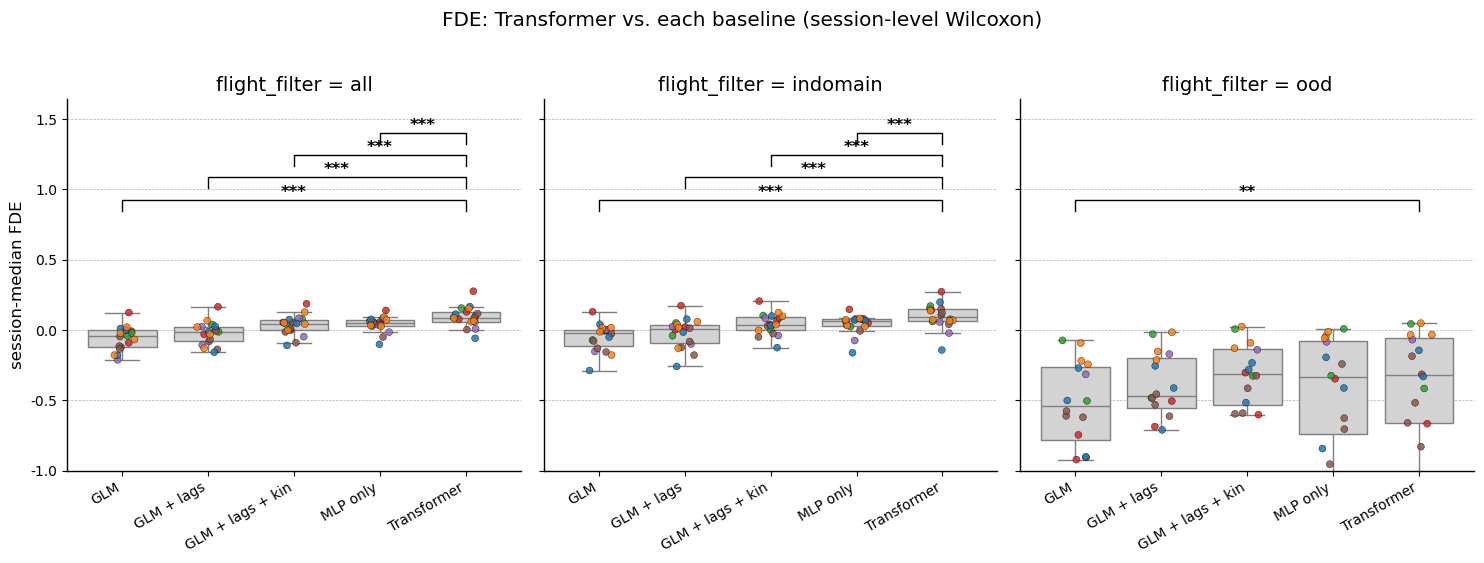

In [93]:
session_wide = session_df.pivot_table(
    index=['metric', 'flight_filter', 'session', 'bat'],
    columns='model', values='score', observed=False,
).reset_index()

# Transformer is the reference; compare against each baseline (longest-span
# bracket first so the closer ones stack above it).
TRANSFORMER_IDX = MODEL_ORDER.index('Transformer')
baseline_pairs = [(b, 'Transformer') for b in MODEL_ORDER if b != 'Transformer']

# Boxplot per metric x flight_filter, with Transformer-vs-baseline brackets.
for metric in ['corr', 'fde']:
    fig, axes = plt.subplots(1, 3, figsize=(15, 5.5), sharey=True)
    for ax, flight_filter in zip(axes, ['all', 'indomain', 'ood']):
        sub_long = session_df[(session_df['metric'] == metric) &
                              (session_df['flight_filter'] == flight_filter)]
        sns.boxplot(data=sub_long, x='model', y='score', order=MODEL_ORDER,
                    color='lightgray', showfliers=False, ax=ax)
        sns.stripplot(data=sub_long, x='model', y='score', order=MODEL_ORDER,
                      hue='bat', palette=BAT_PALETTE, hue_order=list(BAT_PALETTE.keys()),
                      dodge=False, jitter=0.15, size=5, alpha=0.85,
                      edgecolor='k', linewidth=0.3, ax=ax, legend=False)
        sub_wide = session_wide[(session_wide['metric'] == metric) &
                                (session_wide['flight_filter'] == flight_filter)]
        if metric == 'fde':
            ax.set_ylim(-1, 1)
        # Reserve headroom for stacked brackets above the data.
        ymin, ymax = ax.get_ylim()
        span = ymax - ymin
        ax.set_ylim(top=ymax + 0.32 * span)
        ymin, ymax = ax.get_ylim()
        span = ymax - ymin
        # Stack brackets bottom-up. baseline_pairs[0] has the longest span and
        # sits lowest; baseline_pairs[-1] (MLP only vs Transformer, the shortest
        # span) sits highest.
        base_y = ymax - 0.30 * span
        step = 0.06 * span
        for i, (m_a, m_b) in enumerate(baseline_pairs):
            paired = sub_wide[[m_a, m_b]].dropna()
            if len(paired) < 3:
                continue
            _, p = wilcoxon_safe((paired[m_b] - paired[m_a]).values)
            x1 = MODEL_ORDER.index(m_a)
            x2 = MODEL_ORDER.index(m_b)
            add_significance_bracket(ax, x1, x2, p, y=base_y + i * step)
        ax.tick_params(axis='x', rotation=30)
        for lbl in ax.get_xticklabels():
            lbl.set_horizontalalignment('right')
        ax.set_xlabel('')
        ax.set_ylabel(f'session-median {metric.upper()}')
        ax.set_title(f'flight_filter = {flight_filter}')
    fig.suptitle(f'{metric.upper()}: Transformer vs. each baseline (session-level Wilcoxon)', y=1.02)
    plt.tight_layout()
    plt.show()

## Per-neuron `Transformer − baseline` histograms

For each of the four non-Transformer models, plot the per-neuron difference
`Transformer − baseline` colored by bat. One row per baseline, one column per
metric. Vertical dashed line at zero is the no-effect reference; positive
density means Transformer wins for that neuron. FDE x-range clipped to
`[-1, 1]` in the plot only.

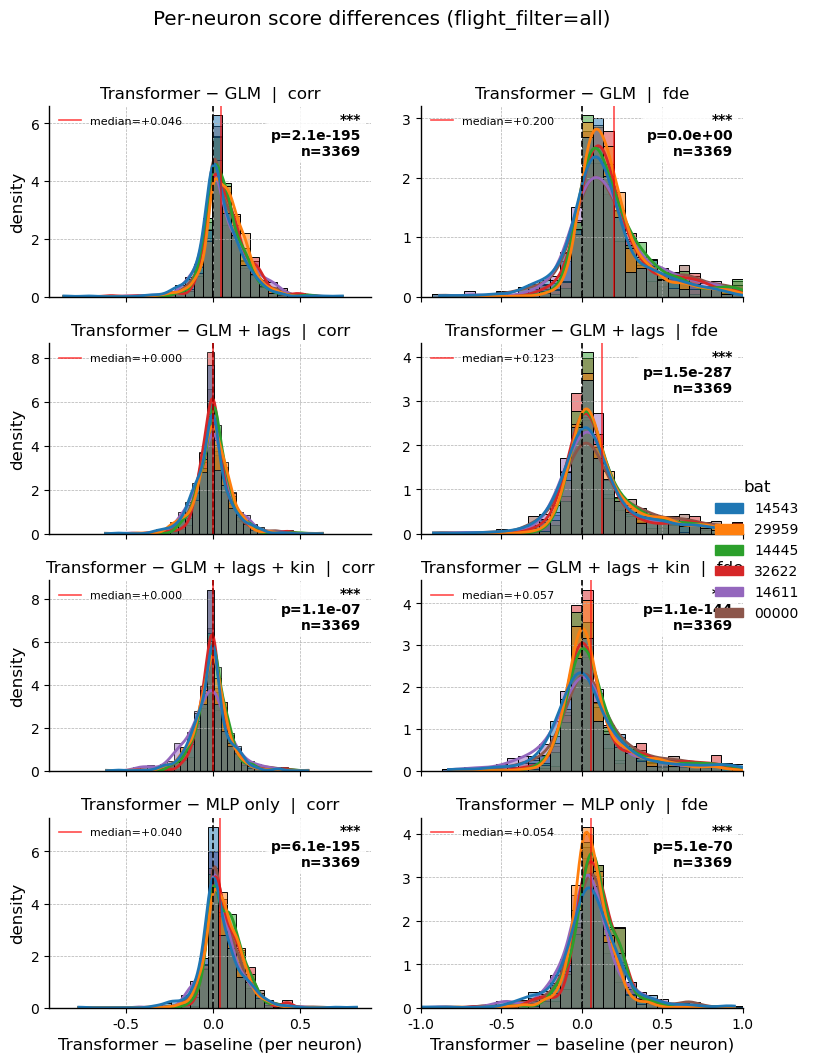

In [94]:
# Use only the 'all' flight filter for the histogram (mirrors the reference notebook).
diff_rows = []
baselines = [m for m in MODEL_ORDER if m != 'Transformer']

for metric in ['corr', 'fde']:
    sub = wide[(wide['metric'] == metric) & (wide['flight_filter'] == 'all')]
    for baseline in baselines:
        diff = (sub['Transformer'] - sub[baseline]).dropna()
        for d, bat in zip(diff, sub.loc[diff.index, 'bat']):
            diff_rows.append({
                'metric': metric, 'comparison': f'Transformer − {baseline}',
                'diff': d, 'bat': bat,
            })
df_diff = pd.DataFrame(diff_rows)

comparison_order = [f'Transformer − {b}' for b in baselines]
df_diff['comparison'] = pd.Categorical(df_diff['comparison'],
                                       categories=comparison_order, ordered=True)

def _hist_panel(data, color=None, **kwargs):
    """Per-facet histogram: FDE values are unbounded below, so we filter the
    visualized range to [-1, 1] and pin the binrange there. Underlying diffs
    stay raw — this only affects the plot (memory rule: clip in plots, not
    in computations)."""
    metric = data['metric'].iloc[0] if len(data) else None
    plot_data, binrange = data, None
    if metric == 'fde':
        plot_data = data[data['diff'].between(-1, 1)]
        binrange = (-1, 1)
    sns.histplot(data=plot_data, x='diff', hue='bat',
                 palette=BAT_PALETTE, hue_order=list(BAT_PALETTE.keys()),
                 bins=30, binrange=binrange, kde=True, alpha=0.5,
                 stat='density', common_norm=False, legend=False)

g = sns.FacetGrid(
    df_diff, col='metric', row='comparison',
    col_order=['corr', 'fde'], row_order=comparison_order,
    height=2.6, aspect=1.5, sharey=False, sharex='col',
)
g.map_dataframe(_hist_panel)
# Combine row+col into a single per-panel title so the right margin stays free.
g.set_titles(template='{row_name}  |  {col_name}')
for (comparison, metric), ax in g.axes_dict.items():
    sub = df_diff[(df_diff['comparison'] == comparison) &
                  (df_diff['metric'] == metric)]
    # Neuron-level Wilcoxon signed-rank: H0 median(diff) = 0.
    # FDE: run stats on the RAW (unclipped) diffs per the project memory rule.
    _, p = wilcoxon_safe(sub['diff'].values)
    median = float(np.median(sub['diff'])) if len(sub) else float('nan')
    ax.axvline(0, color='black', linestyle='--', lw=1.2)
    if np.isfinite(median):
        ax.axvline(median, color='red', linestyle='-', lw=1.2, alpha=0.7,
                   label=f'median={median:+.3f}')
        ax.legend(fontsize=8, loc='upper left', frameon=False)
    if metric == 'fde':
        ax.set_xlim(-1, 1)
    annotate_pvalue_corner(ax, p, n=len(sub))
g.set_axis_labels('Transformer − baseline (per neuron)', 'density')
# Manual bat-color legend (hue is inside each panel, not on FacetGrid).
import matplotlib.patches as mpatches
handles = [mpatches.Patch(color=BAT_PALETTE[b], label=b) for b in BAT_PALETTE]
g.figure.legend(handles=handles, title='bat', loc='center right',
                bbox_to_anchor=(1.05, 0.5), frameon=False)
g.figure.suptitle('Per-neuron score differences (flight_filter=all)', y=1.02)
plt.tight_layout()
plt.show()

## Summary tables

Per-model median across neurons (or sessions) and the full pairwise Wilcoxon
matrix on per-session medians.

In [95]:
neuron_summary = (
    df.groupby(['metric', 'flight_filter', 'model'], observed=True)
      .agg(n_neurons=('score', 'size'),
           neuron_median=('score', 'median'),
           neuron_mean=('score', 'mean'))
      .reset_index()
)
neuron_summary

,metric,flight_filter,model,n_neurons,neuron_median,neuron_mean
0,corr,all,GLM,3369,0.134253,1.899404e-01
1,corr,all,GLM + lags,3369,0.195256,2.509532e-01
2,corr,all,GLM + lags + kin,3369,0.208663,2.599679e-01
3,corr,all,MLP only,3369,0.161543,1.955839e-01
4,corr,all,Transformer,3369,0.218507,2.519704e-01
5,corr,indomain,GLM,3369,0.165891,2.183347e-01
6,corr,indomain,GLM + lags,3369,0.221698,2.735822e-01
7,corr,indomain,GLM + lags + kin,3369,0.234001,2.797951e-01
8,corr,indomain,MLP only,3369,0.167004,2.058197e-01
9,corr,indomain,Transformer,3369,0.221527,2.611789e-01


In [96]:
# Pairwise Wilcoxon signed-rank on per-session medians.
# Alternative: H1 = column model > row model. p < 0.05 means column beats row.
def stars(p):
    if not np.isfinite(p): return ''
    return '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'n.s.'

pair_rows = []
for metric in ['corr', 'fde']:
    for flight_filter in ['all', 'indomain', 'ood']:
        sub = session_wide[(session_wide['metric'] == metric) &
                           (session_wide['flight_filter'] == flight_filter)]
        for m_a in MODEL_ORDER:
            for m_b in MODEL_ORDER:
                if m_a == m_b:
                    continue
                paired = sub[[m_a, m_b]].dropna()
                if len(paired) < 3:
                    continue
                diff = (paired[m_b] - paired[m_a]).values
                try:
                    _, p = wilcoxon(diff, alternative='greater')
                except ValueError:
                    p = np.nan
                pair_rows.append({
                    'metric': metric, 'flight_filter': flight_filter,
                    'row (baseline)': m_a, 'col (alternative)': m_b,
                    'n_sessions': len(paired),
                    'median_diff (col - row)': float(np.median(diff)),
                    'p (col > row)': p, 'sig': stars(p),
                })
pair_df = pd.DataFrame(pair_rows)

print('Transformer vs. each baseline:')
transformer_vs = pair_df[(pair_df['col (alternative)'] == 'Transformer') &
                         (pair_df['row (baseline)'] != 'Transformer')]
transformer_vs[['metric', 'flight_filter', 'row (baseline)', 'col (alternative)',
                'n_sessions', 'median_diff (col - row)', 'p (col > row)', 'sig']]

Transformer vs. each baseline:


,metric,flight_filter,row (baseline),col (alternative),n_sessions,median_diff (col - row),p (col > row),sig
3,corr,all,GLM,Transformer,18,0.078233,0.000004,***
7,corr,all,GLM + lags,Transformer,18,0.024136,0.007965,**
11,corr,all,GLM + lags + kin,Transformer,18,-0.004222,0.319847,n.s.
15,corr,all,MLP only,Transformer,18,0.061315,0.000004,***
23,corr,indomain,GLM,Transformer,18,0.049866,0.000004,***
27,corr,indomain,GLM + lags,Transformer,18,0.000972,0.335262,n.s.
31,corr,indomain,GLM + lags + kin,Transformer,18,-0.019833,0.966732,n.s.
35,corr,indomain,MLP only,Transformer,18,0.056926,0.000004,***
43,corr,ood,GLM,Transformer,16,0.000000,0.008980,**
47,corr,ood,GLM + lags,Transformer,16,0.000000,0.031490,*
